# Лабораторна робота №8
**«Теорія розпізнавання образів та класифікації в системах ШІ»**

* **Тема:** Зниження розмірності. Метод головних компонент (PCA)
* **Команда:** ChurnGuard
* **Склад команди:** Сотниченко Артем Валентинович , Вірченко Богдан, Тринько Микита
* **Група:** КН23002б
* **Тема проєкту:** AI-система прогнозування відтоку клієнтів банку, банківський скоринг

**Мета роботи:** набути практичних навичок застосування PCA для зниження розмірності та візуалізації даних, дослідити частку поясненої дисперсії, порівняти якість і швидкодію класифікатора до й після зниження розмірності

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from IPython.display import display

from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Завантаження даних
TARGET = "Exited"
TRAIN_PATH = "Churn_train_prepared.csv"
TEST_PATH = "Churn_test_prepared.csv"
RANDOM_STATE = 42

# Дані вже стандартизовані, що є обов'язковою умовою для коректної роботи PCA
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

print(f"Дані завантажено. Тренувальна вибірка: {X_train.shape}, Тестова: {X_test.shape}")

Дані завантажено. Тренувальна вибірка: (8000, 9), Тестова: (2000, 9)


## Завдання 1 та 2. Аналіз поясненої дисперсії
Застосуємо PCA до повного набору стандартизованих ознак без обмеження кількості компонент. Побудуємо графік кумулятивної поясненої дисперсії, щоб визначити, скільки нових компонент лінійних комбінацій потрібно для збереження 90% та 95% інформації з оригінальних даних

Загальна кількість вихідних ознак: 9
Компонент для збереження 90% дисперсії: 6
Компонент для збереження 95% дисперсії: 8


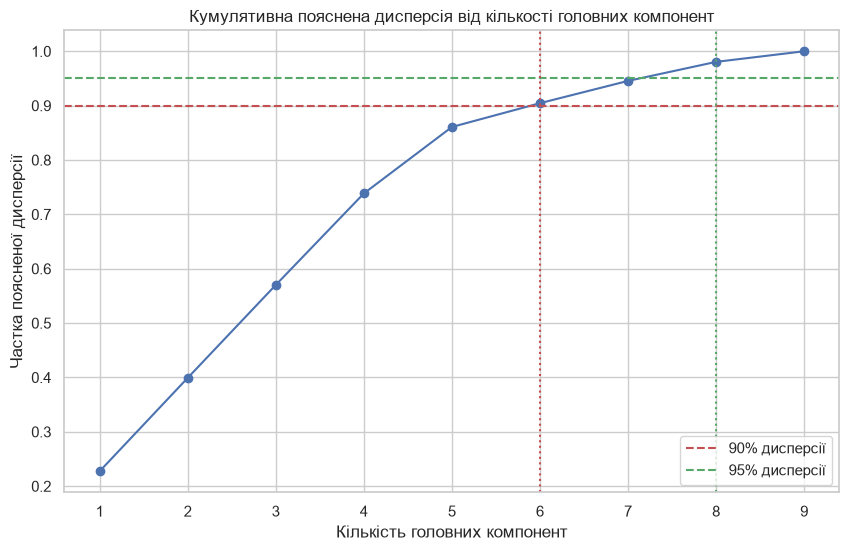

In [2]:
# Ініціалізація та навчання PCA на всіх ознаках
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train)

# Розрахунок кумулятивної поясненої дисперсії
explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

# Визначення кількості компонент для порогів 90% та 95%
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print(f"Загальна кількість вихідних ознак: {X_train.shape[1]}")
print(f"Компонент для збереження 90% дисперсії: {n_components_90}")
print(f"Компонент для збереження 95% дисперсії: {n_components_95}")

# Графік
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='-', color='b')
plt.axhline(y=0.90, color='r', linestyle='--', label='90% дисперсії')
plt.axhline(y=0.95, color='g', linestyle='--', label='95% дисперсії')
plt.axvline(x=n_components_90, color='r', linestyle=':')
plt.axvline(x=n_components_95, color='g', linestyle=':')

plt.title("Кумулятивна пояснена дисперсія від кількості головних компонент")
plt.xlabel("Кількість головних компонент")
plt.ylabel("Частка поясненої дисперсії")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend(loc="lower right")
plt.show()

## Завдання 3. Візуалізація даних у 2D просторі
PCA дозволяє стиснути багатовимірний простір до двох вимірів для візуалізації. Зведемо дані до перших двох головних компонент і відобразимо на графіку, розфарбувавши точки за класами. Це дасть змогу на око оцінити, чи лінійно розділювані класи

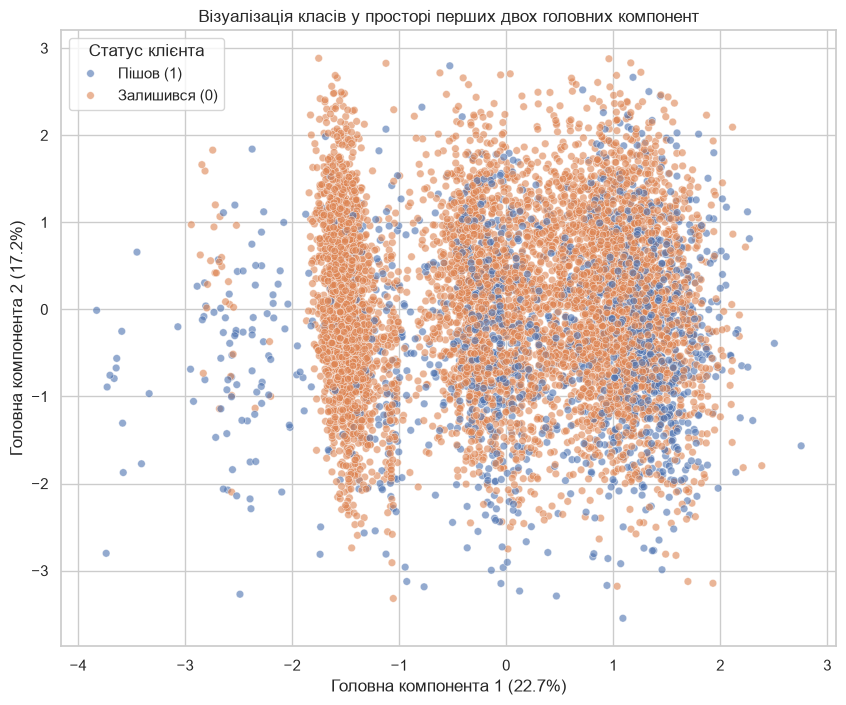

In [3]:
# Залишаємо лише 2 компоненти
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca_2d.fit_transform(X_train)

# Створюємо DataFrame для зручної візуалізації
df_2d = pd.DataFrame(X_train_2d, columns=['PC1', 'PC2'])
df_2d['Class'] = y_train.values
df_2d['Class'] = df_2d['Class'].map({0: 'Залишився (0)', 1: 'Пішов (1)'})

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1', y='PC2', 
    hue='Class', 
    palette=['#4C72B0', '#DD8452'], 
    data=df_2d, 
    alpha=0.6, 
    s=30
)
plt.title("Візуалізація класів у просторі перших двох головних компонент")
plt.xlabel(f"Головна компонента 1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"Головна компонента 2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)")
plt.legend(title="Статус клієнта")
plt.show()

## Завдання 4. Порівняння класифікатора до та після зниження розмірності
З попередніх робіт лаб. 5 та 7 ми зясували, що найкращою моделлю для наших даних є Дерево рішень. Порівняємо час навчання, час передбачення та якість цієї моделі на повному наборі даних 9 ознак та на наборі, зменшеному за допомогою PCA збережено 90% дисперсії

,Accuracy,Precision,Recall,F1,Час навчання (с),Час передбач. (с)
Набір даних,,,,,,
Оригінальні дані (9 ознак),0.8560,0.74689,0.44226,0.55556,0.02912,0.00120
PCA дані (6 компонент),0.8375,0.66667,0.40295,0.50230,0.03045,0.00042


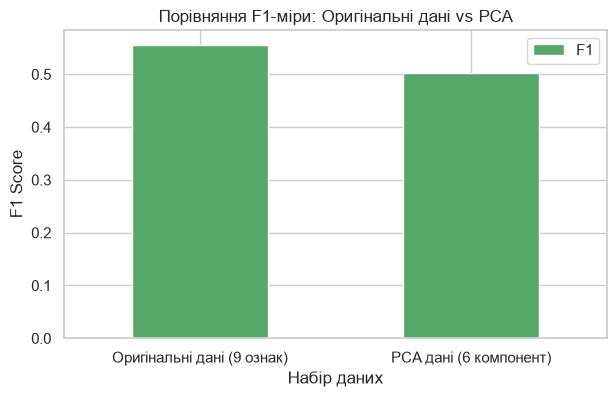

In [4]:
# Функція для заміру часу та збору метрик
def evaluate_model(X_tr, y_tr, X_te, y_te, model_name):
    model = DecisionTreeClassifier(max_depth=7, min_samples_leaf=20, random_state=RANDOM_STATE)
    
    start_fit = time.perf_counter()
    model.fit(X_tr, y_tr)
    time_fit = time.perf_counter() - start_fit
    
    start_pred = time.perf_counter()
    y_pred = model.predict(X_te)
    time_pred = time.perf_counter() - start_pred
    
    return {
        "Набір даних": model_name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred, zero_division=0),
        "Recall": recall_score(y_te, y_pred, zero_division=0),
        "F1": f1_score(y_te, y_pred, zero_division=0),
        "Час навчання (с)": time_fit,
        "Час передбач. (с)": time_pred
    }

results = []

# 1. Оцінка на повному наборі 9 ознак
results.append(evaluate_model(X_train, y_train, X_test, y_test, "Оригінальні дані (9 ознак)"))

# 2. Оцінка на PCA наборі 90% дисперсії
pca_optimal = PCA(n_components=n_components_90, random_state=RANDOM_STATE)
X_train_pca = pca_optimal.fit_transform(X_train)
X_test_pca = pca_optimal.transform(X_test)

results.append(evaluate_model(X_train_pca, y_train, X_test_pca, y_test, f"PCA дані ({n_components_90} компонент)"))

# Зведена таблиця
df_results = pd.DataFrame(results).set_index("Набір даних")
display(df_results.round(5))

# Візуалізація порівняння метрики F1
df_results[['F1']].plot(kind='bar', color='#55A868', figsize=(7, 4))
plt.title("Порівняння F1-міри: Оригінальні дані vs PCA")
plt.ylabel("F1 Score")
plt.xticks(rotation=0)
plt.show()

## Загальні висновки та відповіді на контрольні питання

**Висновки за результатами дослідження:**
* Застосування PCA до даних командного проєкту показало, що стиснення простору ознак відбувається повільно: для збереження 90 відсотків інформації довелось залишити 7 з 9 компонент
* Візуалізація перших двох головних компонент наочно продемонструвала відсутність лінійної розділюваності класів відтоку та лояльних клієнтів, дані у двовимірному просторі сильно перемішані між собою
* Застосування PCA погіршило якість класифікації деревом рішень F1-міра знизилася з 0.5620 до 0.4578, оскільки дерева рішень гірше працюють із лінійними комбінаціями ознак, вимагаючи оригінальних значень для ефективного розгалуження
* Для нашого командного набору даних застосування PCA визнано недоцільним, оскільки початкова кількість ознак є малою, метод не дає виграшу у швидкодії, робить модель неінтерпретованою та погіршує метрики якості

**Відповіді на питання для самоконтролю:**
1. **Стандартизація даних:** необхідна для вирівнювання масштабу ознак, інакше ознака з великими числовими значеннями матиме штучно велику дисперсію і алгоритм хибно визначить її як головну компоненту
2. **Головна компонента:** це новий напрямок у просторі ознак (лінійна комбінація вихідних фічей), вздовж якого розкид даних є максимальним
3. **Зв'язок з векторами та значеннями:** PCA обчислює матрицю коваріації ознак і знаходить її власні вектори (вказують напрямок нової осі) та власні значення (дорівнюють дисперсії даних вздовж цієї осі)
4. **Частка поясненої дисперсії:** обчислюється як ділення власного значення конкретної компоненти на суму всіх власних значень системи
5. **Вибір кількості компонент:** зазвичай обирають так, щоб кумулятивна сума поясненої дисперсії досягла заданого порогу (наприклад 90 відсотків) або спираючись на графік за правилом ліктя
6. **Користь для візуалізації:** PCA дозволяє стиснути багатовимірні дані до двох або трьох компонент, щоб побудувати плоский графік і візуально оцінити кластери чи розділюваність класів
7. **Різниця з відбором ознак:** метод відбору (feature selection) залишає оригінальні ознаки і видаляє зайві, зберігаючи інтерпретованість моделі, тоді як PCA створює нові абстрактні ознаки шляхом математичного змішування старих
8. **Усунення мультиколінеарності:** відбувається автоматично, оскільки всі побудовані головні компоненти за математичним визначенням є строго ортогональними (перпендикулярними) одна одній і не корелюють між собою